# Анализ результатов time-series-hybrid

Сравнение ARIMA, Chronos-2, TimesFM 3 и ARIMA + Chronos-2 на сохранённых результатах.
Ноутбук **не запускает обучение или прогнозирование моделей**. Он читает результаты
и сохраняет таблицы и рисунки в `outputs/<run-id>/analysis/notebook/`.

**Начало работы:** выберите ядро из `.venv` проекта и выполните **Run All**.
По умолчанию выбирается последний завершённый полный запуск с исходными задачами;
smoke-тесты и объединённые отчёты пропускаются. Для воспроизводимого анализа
задайте конкретный `RUN_ID` в следующей ячейке.

Порядок: протокол → общие метрики → ошибки по шагам → интервалы и время →
диагностика ARIMA → ошибки по каналам и окнам → пример прогноза и гибрид.

In [2]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 5)

RUN_ID = None  # Например: "20261031T092812Z-f63e1045"; None = последний полный запуск.
DATASET = "ETTm1"
SEED = 0
HORIZON = None  # None = наибольший из доступных горизонтов.
CHANNEL = None  # None = первый канал; для текущего NPY доступны строки "0" ... "6".
ORIGIN = None   # None = первое test-окно, иначе индекс начала прогнозируемого участка.
COMPUTE_DETAILS = True  # Потоковый расчёт по каналам и окнам; можно отключить.

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pyproject.toml").is_file() and (p / "src/tshybrid").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте ноутбук из каталога time-series-hybrid или notebooks внутри него.")

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def latest_full_run():
    candidates = []
    for path in (ROOT / "outputs").glob("*/manifest.json"):
        info = read_json(path)
        metrics_path = path.parent / "metrics.csv"
        if (info.get("status") != "completed" or not info.get("config")
                or not metrics_path.is_file() or metrics_path.stat().st_size < 2):
            continue
        frame = pd.read_csv(metrics_path)
        if frame.empty or "pilot" not in frame:
            continue
        pilot = frame.pilot.astype(str).str.lower().eq("true")
        if pilot.any() or info["config"].get("purpose") == "pilot":
            continue
        if not all((path.parent / f"{r.dataset}-{r.model}-H{r.horizon}-s{r.seed}").is_dir()
                   for r in frame.itertuples()):
            continue
        candidates.append((info.get("run_id", path.parent.name), path.parent))
    if not candidates:
        raise FileNotFoundError("Полных завершённых запусков нет. Укажите RUN_ID явно для pilot-запуска.")
    return max(candidates, key=lambda item: item[0])[1]

if RUN_ID is None:
    RUN = latest_full_run()
else:
    requested = Path(RUN_ID)
    RUN = requested if requested.is_absolute() else ROOT / "outputs" / requested
RUN = RUN.resolve()
manifest = read_json(RUN / "manifest.json")
if not manifest.get("config"):
    raise ValueError("Выберите исходный запуск с config и predictions, а не объединённый отчёт.")
if manifest.get("status") != "completed":
    raise ValueError(f"Запуск не завершён успешно: {manifest.get('status')}")
metrics_all = pd.read_csv(RUN / "metrics.csv")
metrics = metrics_all[(metrics_all.dataset == DATASET) & (metrics_all.seed == SEED)].copy()
if metrics.empty:
    raise ValueError(f"Нет результатов для dataset={DATASET}, seed={SEED}")
data_info = next(d for d in manifest["datasets"] if d["name"] == DATASET)
horizons = sorted(metrics.horizon.astype(int).unique())
channels = [str(c) for c in data_info["channel_names"]]
HORIZON = int(HORIZON if HORIZON is not None else max(horizons))
CHANNEL = str(CHANNEL if CHANNEL is not None else channels[0])
EXPORT = RUN / "analysis" / "notebook"
EXPORT.mkdir(parents=True, exist_ok=True)

def task_dir(model, horizon, seed=SEED):
    return RUN / f"{DATASET}-{model}-H{int(horizon)}-s{seed}"

def save_figure(fig, name):
    fig.savefig(EXPORT / name, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Запуск:", RUN.name)
print("Статус:", manifest["status"], "| протокол:", manifest["protocol"])
print("Модели:", ", ".join(metrics.model.unique()))
print("Файлы анализа:", EXPORT)
if metrics.pilot.astype(str).str.lower().eq("true").any():
    display(Markdown("**Это pilot/subset: метрики нельзя считать результатом полного эксперимента.**"))

Запуск: 20261031T092812Z-f63e1045
Статус: completed | протокол: common
Модели: arima, chronos2, timesfm3, arima_chronos2
Файлы анализа: C:\workspace\learning\research\time-series-hybrid\outputs\20261031T092812Z-f63e1045\analysis\notebook


## 1. Протокол и воспроизводимость

Проверьте длину ряда, разбиение, число окон и совпадение входных данных у моделей.
Для текущего ETTm1 используются первые 57 600 строк и разбиение 60/20/20;
это протокол проекта, отличный от стандартного календарного разбиения ETT.
Каждый канал прогнозируется независимо, модели Chronos-2 и TimesFM 3 заморожены.

In [3]:
config = manifest["config"]
protocol_table = pd.DataFrame([{
    "dataset": DATASET,
    "used_shape": data_info.get("used_shape"),
    "train_rows": data_info["train_end"],
    "validation_rows": data_info["val_end"] - data_info["train_end"],
    "test_rows": data_info["test_end"] - data_info["val_end"],
    "context": config["context"],
    "frequency": data_info.get("frequency"),
    "device": config.get("device"),
    "seed": SEED,
}])
display(protocol_table)
display(metrics[["model", "horizon", "pilot", "n_origins", "channels", "steps"]])
for horizon, group in metrics.groupby("horizon"):
    for field in ["dataset_sha256", "origins_sha256", "channels_signature", "context", "protocol"]:
        if field in group and group[field].nunique(dropna=False) != 1:
            raise ValueError(f"Несопоставимые результаты: H={horizon}, поле {field}")

models_info = [m for m in manifest.get("models", [])
               if m["dataset"] == DATASET and m["seed"] == SEED]
version_rows = []
for item in models_info:
    meta = item.get("metadata", {})
    if meta.get("checkpoint"):
        version_rows.append({"model": item["model"], "horizon": item["horizon"],
                             "checkpoint": meta["checkpoint"],
                             "revision": meta.get("resolved_revision"),
                             "channel_mode": meta.get("channel_mode"),
                             "point_forecast": meta.get("point_forecast")})
display(pd.DataFrame(version_rows))
print("Ошибки выполнения:", read_json(RUN / "failures.json"))
print("Важно: один seed не даёт оценки разброса между повторными запусками.")

,dataset,used_shape,train_rows,validation_rows,test_rows,context,frequency,device,seed
0,ETTm1,"[57600, 7]",34560,11520,11520,336,15min,cuda:0,0


,model,horizon,pilot,n_origins,channels,steps
0,arima,48,False,11473,7,57600
1,chronos2,48,False,11473,7,57600
2,timesfm3,48,False,11473,7,57600
3,arima_chronos2,48,False,11473,7,57600
4,arima,96,False,11425,7,57600
5,chronos2,96,False,11425,7,57600
6,timesfm3,96,False,11425,7,57600
7,arima_chronos2,96,False,11425,7,57600


,model,horizon,checkpoint,revision,channel_mode,point_forecast
0,chronos2,48,amazon/chronos-2,29ec3766d36d6f73f0696f85560a422f50e8498c,independent,median (q0.5)
1,timesfm3,48,google/timesfm-3.0-pytorch,43046b85ec22d584a13f8098c2ed39c889e129c2,independent,median (q0.5)
2,chronos2,96,amazon/chronos-2,29ec3766d36d6f73f0696f85560a422f50e8498c,independent,median (q0.5)
3,timesfm3,96,google/timesfm-3.0-pytorch,43046b85ec22d584a13f8098c2ed39c889e129c2,independent,median (q0.5)


Ошибки выполнения: []
Важно: один seed не даёт оценки разброса между повторными запусками.


## 2. Общие метрики и польза гибрида

**MSE и MAE: меньше — лучше.** Они считаются после нормализации по train, отдельно
для каждого канала. `mse_raw` и `mae_raw` используют исходные единицы; масштабные
каналы могут сильнее влиять на такие средние. MASE делит абсолютную ошибку
на среднюю сезонную разность в train.

В таблице улучшений **положительный процент означает улучшение гибрида** относительно
указанного baseline, отрицательный — ухудшение. Вывод о пользе гибрида требует
сравнения и с ARIMA, и с отдельным Chronos-2.

,model,horizon,mse,mae,mase,mse_raw,mae_raw
0,timesfm3,48,0.25964,0.29638,0.70612,5.05022,1.02048
1,chronos2,48,0.29445,0.30256,0.72306,5.92358,1.05166
2,arima_chronos2,48,0.67436,0.50987,1.22690,16.67229,1.97295
3,arima,48,0.71653,0.53074,1.27898,17.64759,2.04786
4,timesfm3,96,0.30599,0.32527,0.77619,6.04926,1.14343
5,chronos2,96,0.34568,0.33317,0.79769,7.10428,1.18416
6,arima_chronos2,96,0.66400,0.52092,1.25457,16.13471,2.01668
7,arima,96,0.70041,0.53949,1.30060,16.92799,2.07983


mse               mae         
horizon              48       96       48       96
model                                             
arima           0.71653  0.70041  0.53074  0.53949
arima_chronos2  0.67436  0.66400  0.50987  0.52092
chronos2        0.29445  0.34568  0.30256  0.33317
timesfm3        0.25964  0.30599  0.29638  0.32527

,horizon,baseline,mse_improvement_pct,mae_improvement_pct
0,48,arima,5.88536,3.93352
1,48,chronos2,-129.02288,-68.51929
2,48,timesfm3,-159.72777,-72.03252
3,96,arima,5.19843,3.44373
4,96,chronos2,-92.08642,-56.35090
5,96,timesfm3,-116.99754,-60.14746


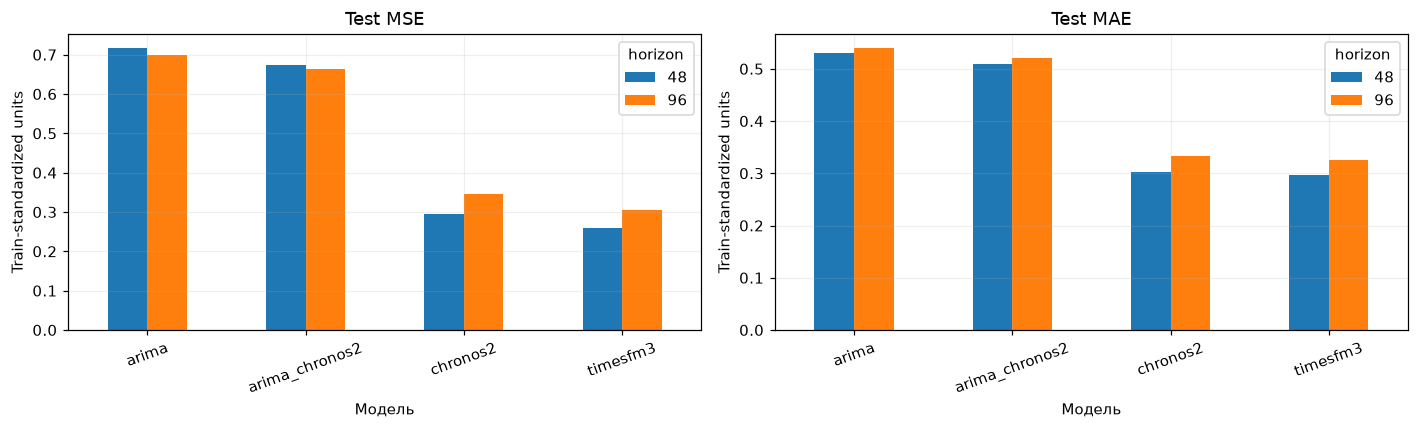

In [ ]:
metric_fields = ["model", "horizon", "mse", "mae", "mase", "mse_raw", "mae_raw"]
display(metrics[metric_fields].sort_values(["horizon", "mse"]).reset_index(drop=True))
display(metrics.pivot(index="model", columns="horizon", values=["mse", "mae"]))

improvements = []
for horizon, group in metrics.groupby("horizon"):
    indexed = group.set_index("model")
    if "arima_chronos2" not in indexed.index:
        continue
    for baseline in ["arima", "chronos2", "timesfm3"]:
        if baseline not in indexed.index:
            continue
        row = {"horizon": horizon, "baseline": baseline}
        for metric in ["mse", "mae"]:
            base = indexed.loc[baseline, metric]
            hybrid = indexed.loc["arima_chronos2", metric]
            row[f"{metric}_improvement_pct"] = 100 * (base - hybrid) / base if base else np.nan
        improvements.append(row)
improvements = pd.DataFrame(improvements)
display(improvements)
metrics.to_csv(EXPORT / "test_metrics.csv", index=False)
improvements.to_csv(EXPORT / "hybrid_improvements.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["mse", "mae"]):
    metrics.pivot(index="model", columns="horizon", values=metric).plot.bar(ax=ax)
    ax.set(title=f"Test {metric.upper()}", xlabel="Модель", ylabel="Train-standardized units")
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
save_figure(fig, "overall_metrics.png")

## 3. Ошибка по шагам прогноза

Каждая точка усреднена по всем test-окнам и каналам для конкретного шага `lead`.
Для ETTm1 один шаг равен 15 минутам. H=48 и H=96 имеют немного разные наборы
окон, поэтому сравнение моделей выполняется внутри одного горизонта.

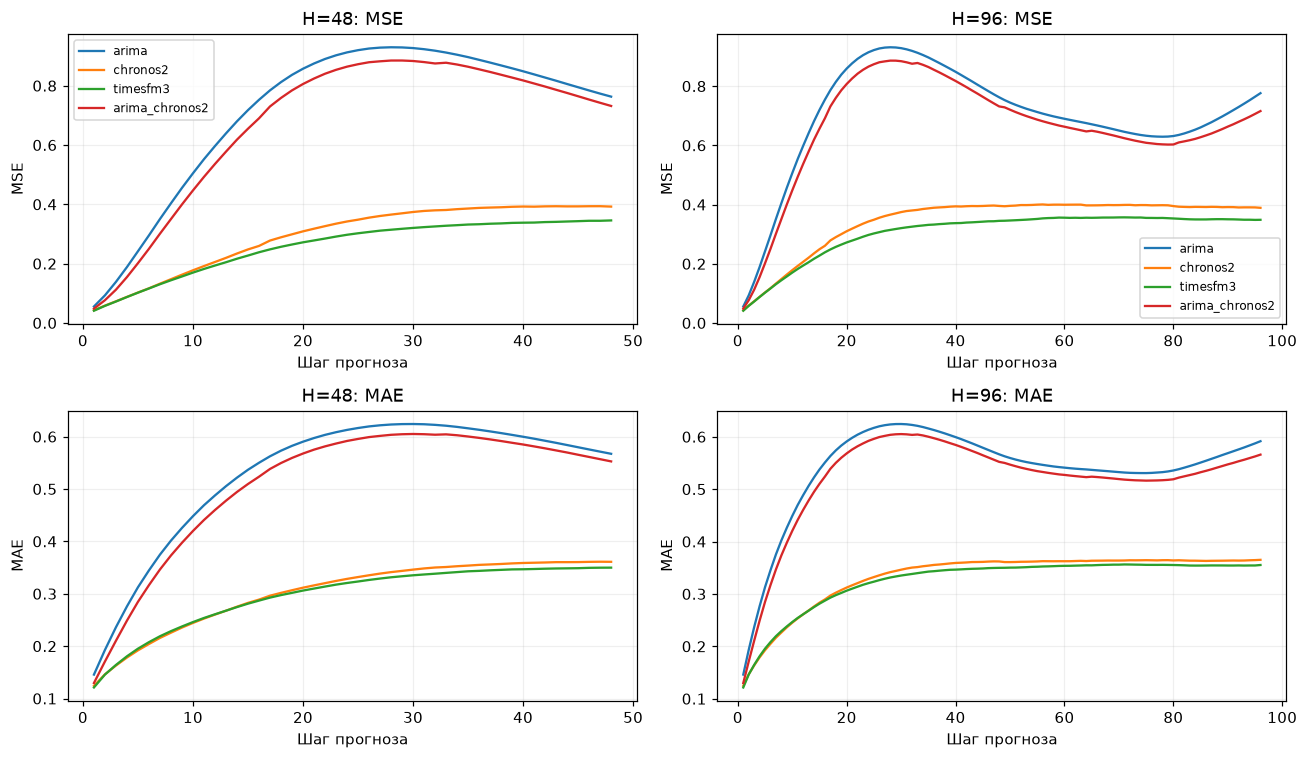

In [5]:
lead_frames = []
for row in metrics.itertuples():
    frame = pd.read_csv(task_dir(row.model, row.horizon) / "by_lead.csv")
    frame["model"], frame["horizon"] = row.model, row.horizon
    lead_frames.append(frame)
by_lead = pd.concat(lead_frames, ignore_index=True)
fig, axes = plt.subplots(2, len(horizons), figsize=(6 * len(horizons), 7), squeeze=False)
for column, horizon in enumerate(horizons):
    for model, frame in by_lead[by_lead.horizon == horizon].groupby("model", sort=False):
        for axis, metric in zip(axes[:, column], ["mse", "mae"]):
            axis.plot(frame.lead, frame[metric], label=model)
            axis.set(title=f"H={horizon}: {metric.upper()}", xlabel="Шаг прогноза", ylabel=metric.upper())
    axes[0, column].legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "errors_by_lead.png")
by_lead.to_csv(EXPORT / "by_lead_all_models.csv", index=False)

## 4. Интервалы и время выполнения

Интервал q0.1–q0.9 имеет номинальное покрытие 80%. Сравнивайте фактическое
`coverage_80` с 0.8 вместе с шириной `width_80`: узкий интервал с низким покрытием
не означает высокую точность. У ARIMA в этом эксперименте интервалы не сохраняются.
У гибрида интервалы описывают неопределённость поправки при фиксированном базовом
прогнозе и не включают всю неопределённость ARIMA.

`selection_seconds` включает выбор по validation и инициализацию; `prediction_seconds`
относится к test-прогнозированию и не является полной длительностью запуска.
Переиспользование загруженных моделей влияет на время между задачами.

,model,horizon,coverage_80,width_80,prediction_seconds,selection_seconds,peak_rss_mb
0,arima,48,NaN,NaN,614.49357,907.53406,610.09375
1,chronos2,48,0.74583,0.80351,200.73018,172.76769,1581.67188
2,timesfm3,48,0.79064,0.91412,1983.34139,2231.72066,3749.33203
3,arima_chronos2,48,0.31859,0.44073,716.19311,724.10004,1697.71484
4,arima,96,NaN,NaN,586.70642,866.04196,1706.79688
5,chronos2,96,0.74785,0.88907,145.85114,146.39873,1704.96875
6,timesfm3,96,0.79198,1.00511,2171.18271,2184.12236,1707.07422
7,arima_chronos2,96,0.30111,0.44685,726.11278,730.71142,1711.74609


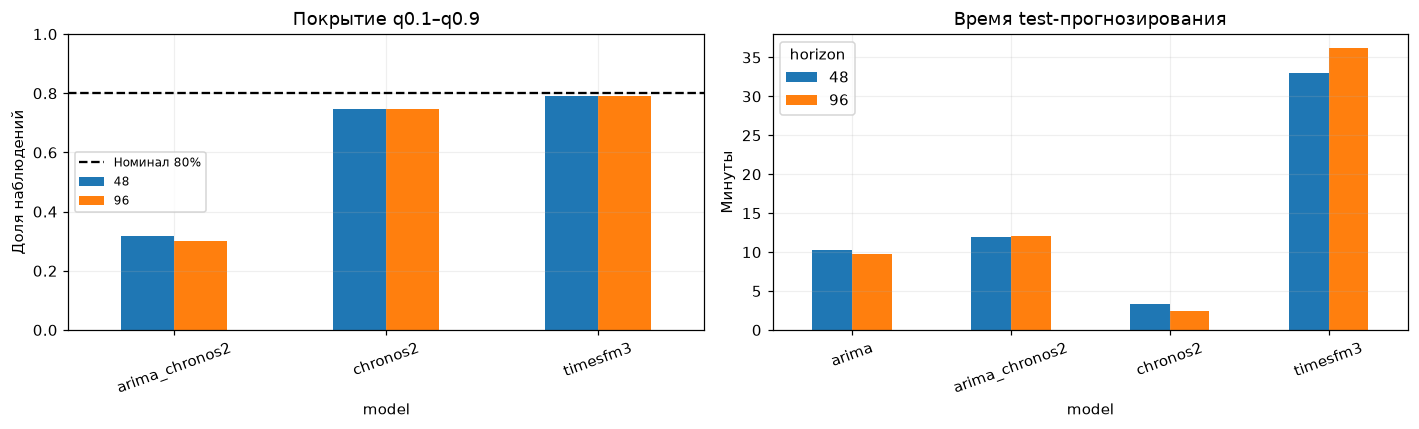

In [6]:
display(metrics[["model", "horizon", "coverage_80", "width_80",
                 "prediction_seconds", "selection_seconds", "peak_rss_mb"]])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
intervals = metrics.dropna(subset=["coverage_80"])
if not intervals.empty:
    intervals.pivot(index="model", columns="horizon", values="coverage_80").plot.bar(ax=axes[0])
axes[0].axhline(0.8, color="black", linestyle="--", label="Номинал 80%")
axes[0].set(title="Покрытие q0.1–q0.9", ylim=(0, 1), ylabel="Доля наблюдений")
axes[0].legend(fontsize=8)
timing = metrics.copy()
timing["test_minutes"] = timing.prediction_seconds / 60
timing.pivot(index="model", columns="horizon", values="test_minutes").plot.bar(ax=axes[1])
axes[1].set(title="Время test-прогнозирования", ylabel="Минуты")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
save_figure(fig, "coverage_and_runtime.png")

## 5. Выбор ARIMA и диагностика сходимости

Порядок ARIMA выбирается по validation MSE, без подбора по test. Таблица ниже
показывает кандидатов и их validation-диагностику. Несходимость оптимизации
не равна ошибке выполнения всего запуска, но требует внимания при интерпретации.
Счётчики в `model.json` могут включать несколько стадий; зависимые модели повторно
используют базу, поэтому их счётчики нельзя просто складывать.

Существующий гибрид прогнозирует **ошибки ARIMA**, а не остатки отдельно
выделенного сглаженного тренда. В выбранном контексте 336 точек параметры ARIMA
оцениваются на первых 128; Chronos-2 получает 208 причинных одношаговых ошибок.

In [7]:
selection = read_json(RUN / "selection.json")
selected_params = {(m["model"], m["horizon"]): m["selected_params"] for m in models_info}
selection_rows = []
warning_rows = []
for item in selection:
    if item.get("dataset") != DATASET or item.get("seed") != SEED:
        continue
    diagnostics = item.get("diagnostics", {})
    calls = diagnostics.get("fit_calls", 0)
    failed = diagnostics.get("nonconverged_fits", 0)
    selection_rows.append({
        "model": item["model"], "horizon": item["horizon"], "candidate": item["candidate"],
        "order": str(item.get("params", {}).get("order", "—")),
        "selected": item.get("params") == selected_params.get((item["model"], item["horizon"])),
        "validation_mse": item.get("validation", {}).get("mse"),
        "validation_fit_calls": calls or None,
        "validation_nonconverged": failed if calls else None,
        "nonconverged_pct": 100 * failed / calls if calls else np.nan,
    })
    for warning, count in diagnostics.get("warning_counts", {}).items():
        warning_rows.append({"model": item["model"], "horizon": item["horizon"],
                             "candidate": item["candidate"], "warning": warning, "count": count})
selection_table = pd.DataFrame(selection_rows)
display(selection_table)
warning_table = pd.DataFrame(warning_rows)
if not warning_table.empty:
    display(warning_table[warning_table.warning.str.startswith("ConvergenceWarning")])
selection_table.to_csv(EXPORT / "validation_selection.csv", index=False)

,model,horizon,candidate,order,selected,validation_mse,validation_fit_calls,validation_nonconverged,nonconverged_pct
0,arima,48,0,"[2, 1, 0]",False,1.17839,80311.0,1525.0,1.89887
1,arima,48,1,"[2, 0, 0]",True,0.96074,80311.0,1789.0,2.22759
2,chronos2,48,0,—,True,0.29602,NaN,NaN,NaN
3,timesfm3,48,0,—,True,0.31389,NaN,NaN,NaN
4,arima_chronos2,48,0,—,True,0.85749,NaN,NaN,NaN
5,arima,96,0,"[2, 1, 0]",False,1.24842,79975.0,1524.0,1.90560
6,arima,96,1,"[2, 0, 0]",True,1.02848,79975.0,1786.0,2.23320
7,chronos2,96,0,—,True,0.39248,NaN,NaN,NaN
8,timesfm3,96,0,—,True,0.42688,NaN,NaN,NaN
9,arima_chronos2,96,0,—,True,0.92877,NaN,NaN,NaN


,model,horizon,candidate,warning,count
1,arima,48,0,ConvergenceWarning: Maximum Likelihood optimiz...,1525
4,arima,48,1,ConvergenceWarning: Maximum Likelihood optimiz...,1789
7,arima,96,0,ConvergenceWarning: Maximum Likelihood optimiz...,1524
10,arima,96,1,ConvergenceWarning: Maximum Likelihood optimiz...,1786


## 6. Метрики по каналам и отдельным test-окнам

Следующая ячейка один раз проходит по Parquet небольшими порциями. Она не загружает
миллионы строк целиком и не вызывает модели. При повторном запуске ячейки расчёт
повторяется; для быстрого просмотра остальных разделов задайте `COMPUTE_DETAILS=False`.

Индексы каналов соответствуют сохранённому NPY; имена датчиков из них не выводятся.
Средняя MSE по окнам должна совпасть с общей test MSE текущего common-протокола.

In [8]:
def aggregate_prediction_file(path):
    channel_parts, origin_parts = [], []
    parquet = pq.ParquetFile(path)
    for batch in parquet.iter_batches(batch_size=131072, columns=[
            "origin", "channel", "y_scaled", "prediction_scaled"]):
        frame = batch.to_pandas()
        error = frame.prediction_scaled.to_numpy(dtype=np.float64) - frame.y_scaled.to_numpy(dtype=np.float64)
        frame["squared_error"] = error ** 2
        frame["absolute_error"] = np.abs(error)
        frame["n_values"] = 1
        for key, parts in [("channel", channel_parts), ("origin", origin_parts)]:
            parts.append(frame.groupby(key)[["squared_error", "absolute_error", "n_values"]].sum())
    results = []
    for parts in [channel_parts, origin_parts]:
        summed = pd.concat(parts).groupby(level=0).sum()
        summed["mse"] = summed.squared_error / summed.n_values
        summed["mae"] = summed.absolute_error / summed.n_values
        results.append(summed.reset_index())
    return results

channel_metrics = pd.DataFrame()
origin_metrics = pd.DataFrame()
if COMPUTE_DETAILS:
    per_channel, per_origin = [], []
    for row in metrics.itertuples():
        ch, origins = aggregate_prediction_file(task_dir(row.model, row.horizon) / "predictions.parquet")
        reconstructed = origins.squared_error.sum() / origins.n_values.sum()
        if manifest["protocol"] == "common":
            np.testing.assert_allclose(reconstructed, row.mse, rtol=1e-6, atol=1e-9)
        for frame in [ch, origins]:
            frame["model"], frame["horizon"], frame["seed"] = row.model, row.horizon, row.seed
        per_channel.append(ch)
        per_origin.append(origins)
        print(f"Готово: {row.model}, H={row.horizon}; MSE={reconstructed:.6f}")
    channel_metrics = pd.concat(per_channel, ignore_index=True)
    origin_metrics = pd.concat(per_origin, ignore_index=True)
    channel_metrics.to_csv(EXPORT / "per_channel_metrics.csv", index=False)
    origin_metrics.to_csv(EXPORT / "per_origin_metrics.csv", index=False)
    display(channel_metrics[["model", "horizon", "channel", "mse", "mae"]])
else:
    print("Подробный расчёт пропущен; общие метрики и просмотр окон доступны.")

Готово: arima, H=48; MSE=0.716533
Готово: chronos2, H=48; MSE=0.294452
Готово: timesfm3, H=48; MSE=0.259642
Готово: arima_chronos2, H=48; MSE=0.674362
Готово: arima, H=96; MSE=0.700405
Готово: chronos2, H=96; MSE=0.345675
Готово: timesfm3, H=96; MSE=0.305992
Готово: arima_chronos2, H=96; MSE=0.663995


,model,horizon,channel,mse,mae
0,arima,48,0,1.74023,0.90981
1,arima,48,1,0.32067,0.44298
2,arima,48,2,1.90030,0.94278
3,arima,48,3,0.26522,0.40175
4,arima,48,4,0.61987,0.60015
5,arima,48,5,0.12982,0.27285
6,arima,48,6,0.03962,0.14488
7,chronos2,48,0,0.58954,0.42553
8,chronos2,48,1,0.17290,0.29970
9,chronos2,48,2,0.58972,0.41243


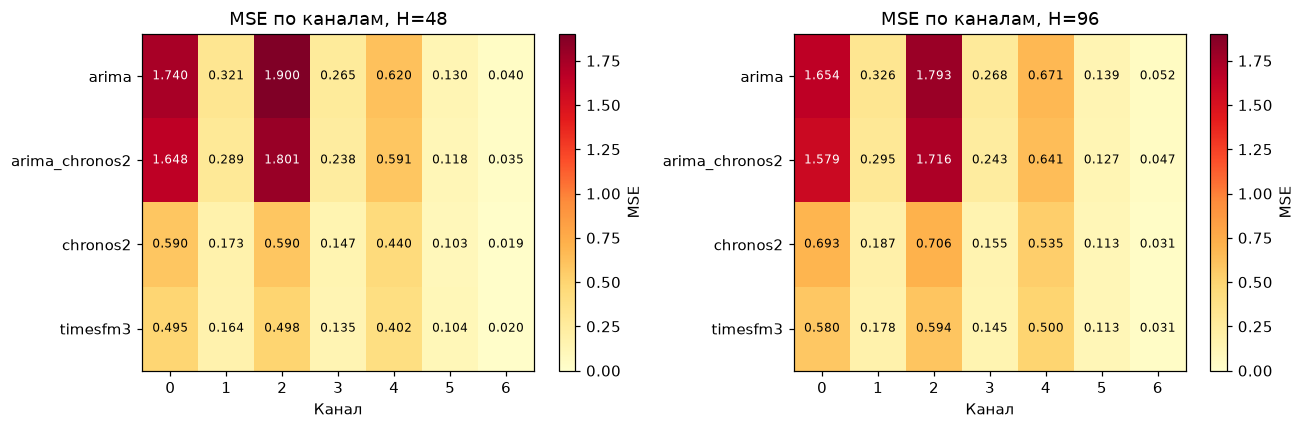

,horizon,baseline,paired_windows,hybrid_better_windows_pct,mean_mse_difference_hybrid_minus_baseline
0,48,arima,11473,89.28789,-0.04217
1,48,chronos2,11473,18.07722,0.37991
2,48,timesfm3,11473,14.42517,0.41472
3,96,arima,11425,92.42888,-0.03641
4,96,chronos2,11425,22.73961,0.31832
5,96,timesfm3,11425,17.63676,0.35800


**Перекрывающиеся окна зависимы.** Доля выигранных окон — описательная статистика, а не p-value или доказательство значимости.

Пять окон с наибольшей MSE для **arima_chronos2**, H=96. Индекс `origin` можно использовать ниже.

,origin,model,mse,mae
87715,53628,arima_chronos2,2.64649,1.22545
87716,53629,arima_chronos2,2.60086,1.21966
90210,56123,arima_chronos2,2.57008,1.00788
87717,53630,arima_chronos2,2.56413,1.21184
90209,56122,arima_chronos2,2.56025,1.00162


In [9]:
if not channel_metrics.empty:
    fig, axes = plt.subplots(1, len(horizons), figsize=(6 * len(horizons), 4), squeeze=False)
    vmax = float(channel_metrics.mse.max()) or 1
    for ax, horizon in zip(axes[0], horizons):
        grid = channel_metrics[channel_metrics.horizon == horizon].pivot(
            index="model", columns="channel", values="mse")
        image = ax.imshow(grid.to_numpy(), aspect="auto", cmap="YlOrRd", vmin=0, vmax=vmax)
        ax.set_xticks(range(len(grid.columns)), labels=grid.columns)
        ax.set_yticks(range(len(grid.index)), labels=grid.index)
        ax.set(title=f"MSE по каналам, H={horizon}", xlabel="Канал")
        ax.grid(False)
        for i in range(len(grid.index)):
            for j in range(len(grid.columns)):
                value = grid.iloc[i, j]
                ax.text(j, i, f"{value:.3f}", ha="center", va="center",
                        color="white" if value > vmax * 0.65 else "black", fontsize=8)
        fig.colorbar(image, ax=ax, label="MSE")
    fig.tight_layout()
    save_figure(fig, "mse_by_channel.png")

    paired_rows = []
    for horizon in horizons:
        wide = origin_metrics[origin_metrics.horizon == horizon].pivot(index="origin", columns="model", values="mse")
        if "arima_chronos2" not in wide:
            continue
        for baseline in ["arima", "chronos2", "timesfm3"]:
            if baseline not in wide:
                continue
            paired = wide[["arima_chronos2", baseline]].dropna()
            paired_rows.append({"horizon": horizon, "baseline": baseline, "paired_windows": len(paired),
                                "hybrid_better_windows_pct": 100 * (paired.arima_chronos2 < paired[baseline]).mean(),
                                "mean_mse_difference_hybrid_minus_baseline": (paired.arima_chronos2 - paired[baseline]).mean()})
    display(pd.DataFrame(paired_rows))
    display(Markdown("**Перекрывающиеся окна зависимы.** Доля выигранных окон — описательная статистика, а не p-value или доказательство значимости."))
    chosen = origin_metrics[origin_metrics.horizon == HORIZON]
    example_model = "arima_chronos2" if "arima_chronos2" in chosen.model.values else chosen.model.iloc[0]
    display(Markdown(f"Пять окон с наибольшей MSE для **{example_model}**, H={HORIZON}. Индекс `origin` можно использовать ниже."))
    display(chosen[chosen.model == example_model].nlargest(5, "mse")[["origin", "model", "mse", "mae"]])

## 7. Просмотр окна и компонентов гибрида

По умолчанию показывается первое test-окно первого канала, без выбора по качеству.
Измените `HORIZON`, `CHANNEL`, `ORIGIN` в первой ячейке либо используйте форму ниже.
Индекс `origin` обозначает первое неизвестное наблюдение, а не календарную дату.

Верхний график показывает прогнозы в исходных единицах. Для гибрида дополнительно
показаны база, итог и поправка. Линия `observed - ARIMA` — **реализовавшаяся
многошаговая ошибка базового прогноза на выбранном test-окне**. Она служит только
для анализа и не является входом Chronos-2; его вход — доступные до origin
одношаговые ошибки ARIMA.

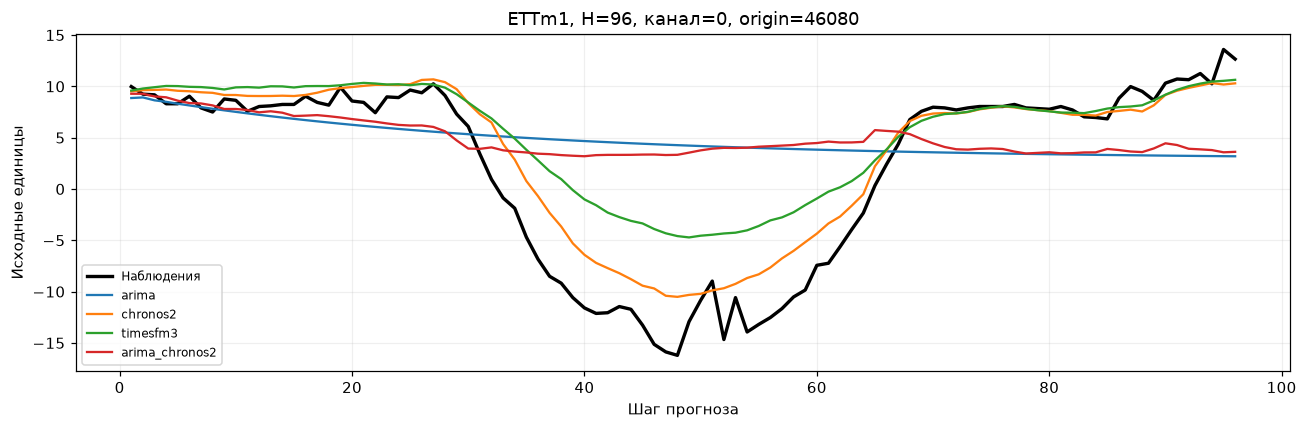

,model,mse,mae
1,chronos2,0.23399,0.36027
2,timesfm3,0.80548,0.62675
3,arima_chronos2,2.28355,1.14161
0,arima,2.48310,1.20492


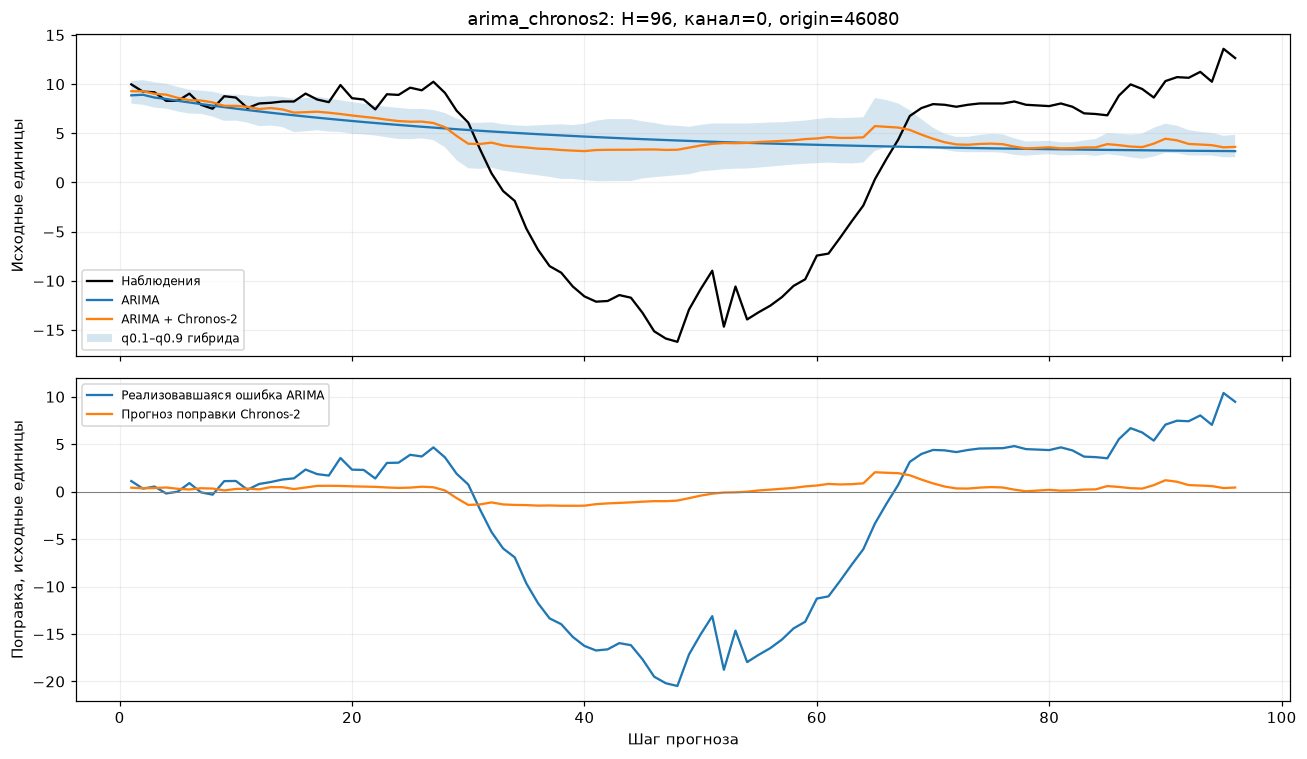

In [10]:
def available_origins(horizon):
    rows = metrics[metrics.horizon == int(horizon)]
    if rows.empty:
        raise ValueError(f"Нет горизонта {horizon}")
    shared = None
    for row in rows.itertuples():
        with np.load(task_dir(row.model, horizon) / "origins.npz") as data:
            values = data["test"].copy()
        shared = values if shared is None else np.intersect1d(shared, values)
    if shared is None or not len(shared):
        raise ValueError("Нет общих test-окон у моделей")
    return shared

def plot_window(horizon, channel, origin=None):
    horizon, channel = int(horizon), str(channel)
    origins = available_origins(horizon)
    origin = int(origins[0] if origin is None else origin)
    if origin not in origins:
        raise ValueError(f"origin={origin} отсутствует. Допустимые индексы: {origins[0]}..{origins[-1]}, с учётом stride.")
    if channel not in channels:
        raise ValueError(f"Неизвестный канал. Доступны {channels}")
    rows = metrics[metrics.horizon == horizon]
    frames = {}
    for row in rows.itertuples():
        frame = pd.read_parquet(task_dir(row.model, horizon) / "predictions.parquet",
                                filters=[("origin", "==", origin), ("channel", "==", channel)]).sort_values("lead")
        if len(frame) != horizon or frame.lead.nunique() != horizon:
            raise ValueError(f"Неполное окно для {row.model}: {len(frame)} строк")
        frames[row.model] = frame
    truth = next(iter(frames.values()))
    for frame in frames.values():
        np.testing.assert_allclose(frame.y, truth.y)
    slug = re.sub(r"[^A-Za-z0-9_-]", "_", f"H{horizon}-channel{channel}-origin{origin}")
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(truth.lead, truth.y, color="black", linewidth=2.2, label="Наблюдения")
    window_rows = []
    for model, frame in frames.items():
        ax.plot(frame.lead, frame.prediction, label=model)
        error = frame.prediction_scaled.to_numpy(dtype=float) - frame.y_scaled.to_numpy(dtype=float)
        window_rows.append({"model": model, "mse": np.mean(error ** 2), "mae": np.mean(np.abs(error))})
    ax.set(title=f"{DATASET}, H={horizon}, канал={channel}, origin={origin}",
           xlabel="Шаг прогноза", ylabel="Исходные единицы")
    ax.legend(fontsize=8)
    fig.tight_layout()
    save_figure(fig, f"forecast-{slug}.png")
    display(pd.DataFrame(window_rows).sort_values("mse"))

    for model, frame in frames.items():
        if "base_prediction" not in frame:
            continue
        np.testing.assert_allclose(frame.prediction, frame.base_prediction + frame.correction, rtol=1e-5, atol=1e-5)
        fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
        axes[0].plot(frame.lead, frame.y, color="black", label="Наблюдения")
        axes[0].plot(frame.lead, frame.base_prediction, label="ARIMA")
        axes[0].plot(frame.lead, frame.prediction, label="ARIMA + Chronos-2")
        if {"q0.1", "q0.9"}.issubset(frame.columns):
            axes[0].fill_between(frame.lead, frame["q0.1"], frame["q0.9"], alpha=0.18, label="q0.1–q0.9 гибрида")
        axes[0].set(title=f"{model}: H={horizon}, канал={channel}, origin={origin}", ylabel="Исходные единицы")
        axes[1].plot(frame.lead, frame.y - frame.base_prediction, label="Реализовавшаяся ошибка ARIMA")
        axes[1].plot(frame.lead, frame.correction, label="Прогноз поправки Chronos-2")
        axes[1].axhline(0, color="gray", linewidth=0.7)
        axes[1].set(xlabel="Шаг прогноза", ylabel="Поправка, исходные единицы")
        for ax in axes:
            ax.legend(fontsize=8)
        fig.tight_layout()
        save_figure(fig, f"{model}-components-{slug}.png")
    return frames

window_frames = plot_window(HORIZON, CHANNEL, ORIGIN)

In [ ]:
# Интерактивная форма. Построение запускается кнопкой, а не при каждом изменении поля.
try:
    import ipywidgets as widgets

    horizon_control = widgets.Dropdown(options=horizons, value=HORIZON, description="Горизонт:")
    channel_control = widgets.Dropdown(options=channels, value=CHANNEL, description="Канал:")
    initial_origins = available_origins(HORIZON)
    initial_origin = int(initial_origins[0] if ORIGIN is None else ORIGIN)
    origin_control = widgets.IntText(value=initial_origin, description="Origin:")
    range_label = widgets.Label()
    draw_button = widgets.Button(description="Построить", button_style="primary")
    output_widget = widgets.Output()

    def update_range(change=None):
        values = available_origins(horizon_control.value)
        range_label.value = f"Test: {values[0]}..{values[-1]}, всего {len(values)} общих окон"
        if origin_control.value not in values:
            origin_control.value = int(values[0])

    def draw_window(_):
        with output_widget:
            output_widget.clear_output(wait=True)
            try:
                plot_window(horizon_control.value, channel_control.value, origin_control.value)
            except (ValueError, FileNotFoundError) as error:
                print(error)

    horizon_control.observe(update_range, names="value")
    draw_button.on_click(draw_window)
    update_range()
    display(widgets.VBox([widgets.HBox([horizon_control, channel_control]),
                          widgets.HBox([origin_control, draw_button]), range_label, output_widget]))
except ImportError:
    print("Для формы установите ipywidgets. Без формы используйте plot_window(96, '0', 47000).")

## 8. Как формулировать выводы

1. Назовите лучший результат **внутри этого запуска и протокола**, отдельно для H=48 и H=96.
2. Для гибрида укажите улучшение относительно ARIMA и сравнение с отдельным Chronos-2.
3. По графикам lead и каналов проверьте, где сосредоточено ухудшение.
4. Рассмотрите покрытие интервалов вместе с их шириной и диагностикой ARIMA.
5. Примеры отдельных окон объясняют поведение, но не заменяют общие test-метрики.

Различие в средних ошибках одного запуска не является проверкой статистической
значимости. Перекрывающиеся окна зависимы; для доверительных интервалов нужна
отдельная процедура с учётом временной зависимости.

**Экспорт:** все рисунки PNG и сводные таблицы CSV уже сохранены в указанной ниже папке.
Исходные `metrics.csv`, Parquet и конфигурация запуска не изменяются.
Для анализа другого эксперимента измените `RUN_ID` и повторите Run All.

In [12]:
print(EXPORT)
display(pd.DataFrame([{"file": p.name, "size_kb": round(p.stat().st_size / 1024, 1)}
                      for p in sorted(EXPORT.iterdir()) if p.is_file()]))

C:\workspace\learning\research\time-series-hybrid\outputs\20261031T092812Z-f63e1045\analysis\notebook


,file,size_kb
0,analysis_results.html,1092.1
1,arima_chronos2-components-H96-channel0-origin4...,158.0
2,by_lead_all_models.csv,112.3
3,coverage_and_runtime.png,63.9
4,errors_by_lead.png,212.8
5,forecast-H96-channel0-origin46080.png,113.7
6,hybrid_improvements.csv,0.3
7,mse_by_channel.png,94.0
8,overall_metrics.png,48.7
9,per_channel_metrics.csv,5.6
